# Verificación con una GAN de librería
Se repite el cálculo del VaR 95% con la `VanillaGAN` de **ydata-synthetic 1.4.0** (TensorFlow) para comprobar que los resultados de la GAN propia (PyTorch, `src/gan.py`) no dependen de errores de implementación. Mismo esquema: ventana móvil de 500 días, re-entrenamiento diario, 500 escenarios, backtest a 20 días.

**Entorno.** La librería no instala en Python 3.14 (`venvpro`): sus versiones ≥ 2.0 son un paquete obsoleto vacío y la 1.4.0 exige Python < 3.12. Se creó un entorno aparte `gan_lib` (Python 3.11) y los scripts `src/02_var_redes_gan_libreria.py` y `src/verifica_libreria.py` se ejecutan allí; este notebook solo lee sus resultados.

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import config, utils, plotstyle
plotstyle.apply()
pd.options.display.float_format = "{:.4f}".format

R = config.RESULTS_DIR
MODELOS = {   # nombre: (serie de VaR, escenarios en t0, color, marcador)
    "GAN propia":               ("var_gan.csv",               "escenarios_gan_t0.csv",               plotstyle.C_GAN,     "o"),
    "Monte Carlo":              ("var_montecarlo.csv",        "escenarios_mc_t0.csv",                plotstyle.C_MC,      "s"),
    "GAN librería (corregida)": ("var_gan_lib_corregida.csv", "escenarios_gan_lib_corregida_t0.csv", plotstyle.C_LIB_FIX, "^"),
    "GAN librería (defecto)":   ("var_gan_lib_defecto.csv",   "escenarios_gan_lib_defecto_t0.csv",   plotstyle.C_LIB_DEF, "D"),
}
var = {m: pd.read_csv(R / v[0], index_col=0, parse_dates=True) for m, v in MODELOS.items()}
train = utils.train_window(utils.load_returns().values, 0)
hist_port = utils.portfolio_return(train)
scen = {m: pd.read_csv(R / v[1]).values for m, v in MODELOS.items()}

## 1. Dos comportamientos de la librería que afectan a esta tarea
Detectados al leer su código y comprobados con `src/verifica_libreria.py` (sin entrenar):

In [2]:
v = json.loads((R / "verificacion_libreria.json").read_text())
pd.DataFrame({
    "comprobación": [
        "Filas distintas que ve fit() con batch_size=128",
        "Filas distintas que ve fit() con batch_size=500",
        "fit() entrena con ruido normal (tf.random.normal)",
        ".sample() genera ruido uniforme (random.uniform)"],
    "resultado": [f'{v["filas_distintas_batch_128"]} de {v["filas_totales"]}',
                  f'{v["filas_distintas_batch_500"]} de {v["filas_totales"]}',
                  v["fit_usa_ruido_normal"], v["sample_usa_ruido_uniforme"]]}).set_index("comprobación")

,resultado
comprobación,
Filas distintas que ve fit() con batch_size=128,128 de 500
Filas distintas que ve fit() con batch_size=500,500 de 500
fit() entrena con ruido normal (tf.random.normal),True
.sample() genera ruido uniforme (random.uniform),True


- `fit` pide cada lote con la misma semilla, así que con lotes menores que la muestra **entrena siempre con las mismas filas**.
- `.sample()` alimenta al generador con ruido uniforme aunque se entrenó con ruido normal.

Por eso se ejecutan dos variantes: **defecto** (uso documentado: `fit` + `.sample()`, batch 128) y **corregida** (lote de 500 = toda la muestra, y muestreo con ruido normal). La corregida es la más favorable a la librería que permite su API sin tocar su código.

## 2. Backtest a 20 días

In [3]:
bt = pd.read_csv(R / "backtest_resumen.csv", index_col=0)
cols = ["excepciones", "esperadas", "kupiec_p", "VaR_medio", "perdida_cuantilica"]
bt.loc[list(MODELOS), cols].T

,GAN propia,Monte Carlo,GAN librería (corregida),GAN librería (defecto)
excepciones,3.0000,2.0000,6.0000,8.0000
esperadas,1.0000,1.0000,1.0000,1.0000
kupiec_p,0.0937,0.3634,0.0003,0.0000
VaR_medio,0.0180,0.0206,0.0098,0.0090
perdida_cuantilica,0.0024,0.0027,0.0045,0.0056


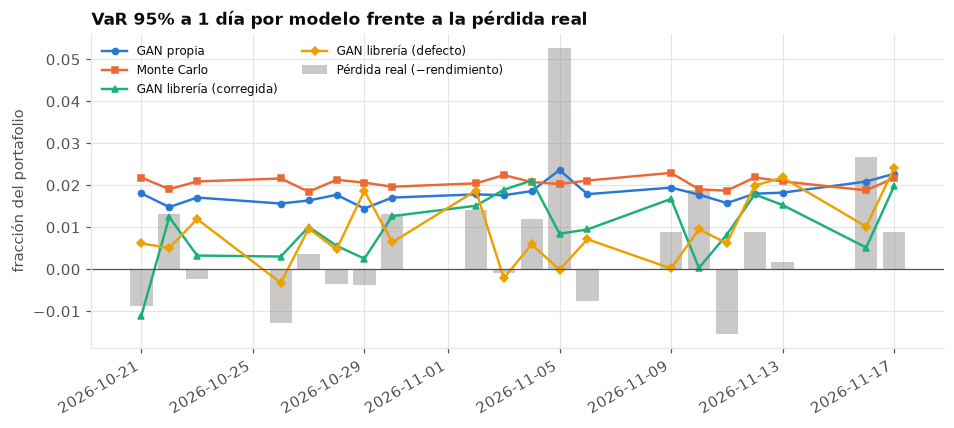

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
real = var["GAN propia"]["realized_return"]
ax.bar(real.index, -real, color=plotstyle.C_HIST, alpha=0.45, width=0.8, label="Pérdida real (−rendimiento)")
for m, (_, _, c, mk) in MODELOS.items():
    ax.plot(var[m].index, var[m]["var_95"], color=c, marker=mk, ms=4, label=m)
ax.axhline(0, color=plotstyle.INK2, lw=0.8)
ax.set_title("VaR 95% a 1 día por modelo frente a la pérdida real"); ax.set_ylabel("fracción del portafolio")
ax.legend(fontsize=8, ncol=2, loc="upper left"); fig.autofmt_xdate()
plotstyle.save(fig, "05_var_modelos"); plt.show()

## 3. Distribución generada en t0 (primer día del backtest)

In [5]:
rows = {"Historial (500 d)": hist_port}
rows.update({m: utils.portfolio_return(s) for m, s in scen.items()})
sd = {"Historial (500 d)": train.std(0)}; sd.update({m: s.std(0) for m, s in scen.items()})
tab = pd.DataFrame({m: {"VaR 95%": utils.var_es(p)[0], "ES 95%": utils.var_es(p)[1],
                        "media": p.mean(), "desv. portafolio": p.std(),
                        **{f"desv. {t}": sd[m][i] for i, t in enumerate(config.TICKERS)}}
                    for m, p in rows.items()}).T
tab

,VaR 95%,ES 95%,media,desv. portafolio,desv. NVDA,desv. JPM,desv. XOM
Historial (500 d),0.0169,0.0292,0.0011,0.0133,0.0276,0.0154,0.0156
GAN propia,0.0181,0.0233,0.0013,0.0105,0.0226,0.0142,0.0146
Monte Carlo,0.0219,0.0287,0.0008,0.0141,0.0289,0.0157,0.0152
GAN librería (corregida),-0.0110,-0.0064,0.0329,0.0160,0.0351,0.0068,0.0125
GAN librería (defecto),0.0061,0.0077,0.0006,0.0043,0.0083,0.0042,0.0036


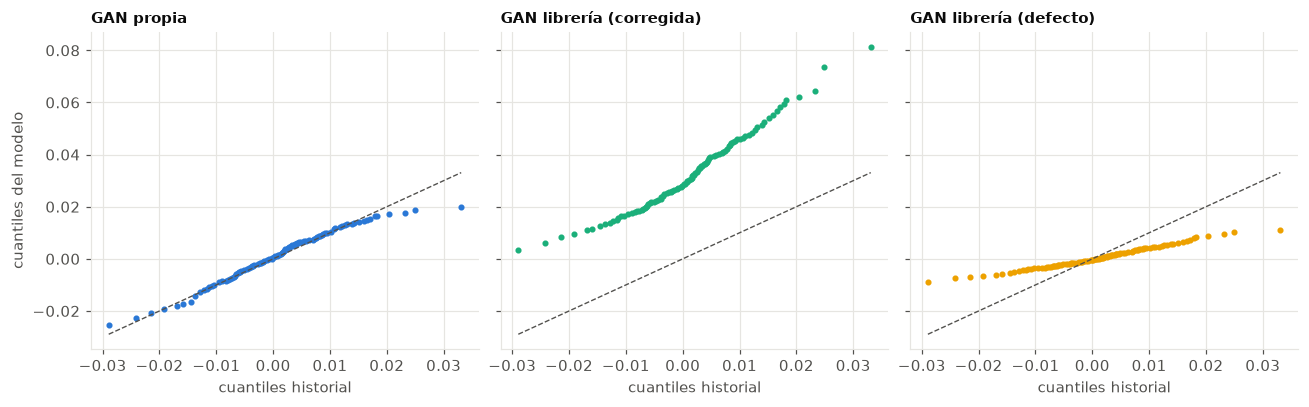

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
qs = np.linspace(0.01, 0.99, 99); qh = np.quantile(hist_port, qs)
for ax, m in zip(axes, ["GAN propia", "GAN librería (corregida)", "GAN librería (defecto)"]):
    qm = np.quantile(utils.portfolio_return(scen[m]), qs)
    ax.scatter(qh, qm, s=9, color=MODELOS[m][2]); lim = [qh.min(), qh.max()]
    ax.plot(lim, lim, color=plotstyle.INK2, lw=0.9, ls="--"); ax.set_title(m, fontsize=10)
    ax.set_xlabel("cuantiles historial")
axes[0].set_ylabel("cuantiles del modelo")
plt.tight_layout(); plotstyle.save(fig, "05_qq_libreria"); plt.show()

## Conclusiones de la verificación
- **La GAN de librería, con su configuración estándar, no produce VaR utilizables en estos datos.** Excepciones en 20 días (se espera 1): 8 en la variante *defecto* y 6 en la *corregida*, frente a 3 de la GAN propia y 2 de Monte Carlo. Kupiec rechaza a ambas variantes de librería (p ≈ 0.0000 y 0.0003) y no rechaza a la GAN propia (p = 0.094) ni a Monte Carlo (p = 0.363). Su VaR medio es ~0.9–1.0%, la mitad del de los otros modelos (1.8–2.1%), es decir, subestima el riesgo de forma sistemática.
- **Los dos fallos tienen causas distintas.** La variante *defecto* está subdispersa: la desviación del portafolio generado es 0.43% frente a 1.33% histórica. La variante *corregida* está **desplazada**: sus escenarios tienen una media de +3.29% diaria (histórica: +0.11%), por lo que el VaR de t0 sale negativo (−1.10%), es decir, el modelo no prevé pérdidas al 5%.
- **Las dos correcciones aplicadas importan, pero no bastan.** Con lote completo y ruido normal la dispersión de NVDA mejora (3.5% frente a 2.8% histórica), pero el generador queda mal centrado.
- **Qué sí se puede afirmar:** la GAN propia no es un caso aislado por un error de implementación; una GAN estándar de librería, sin ajuste, rinde peor. **Qué no:** no demuestra que la librería no pueda funcionar. Se probó una sola configuración con los hiperparámetros comunes de la GAN propia, sin explorar arquitectura ni preprocesado. Una diferencia plausible es el escalado: la librería usa MinMax, que comprime las colas de rendimientos con eventos extremos, mientras que la GAN propia estandariza con media y desviación. No se comprobó que sea la causa.
- **Coste:** en estas ejecuciones cada entrenamiento tardó entre 110 y 220 s (TensorFlow, 8 procesos en paralelo) frente a 18–30 s de la GAN propia (PyTorch); no es una comparación controlada de velocidad.
- **No evaluado:** TimeGAN (referencia 3 del proyecto), que sí modela dependencia temporal y está en la misma librería. Requiere ventanas de varios días y es bastante más costoso de entrenar.
- **Elección del finalista:** no cambia. Sigue decidiéndose solo entre GAN propia y Monte Carlo (ver notebook 04); las variantes de librería quedan fuera del ranking por no ser competitivas.